# Análisis del uso del ordenador
Proyecto de Seguridad y alta disponibilidad (ASIX2) - Adri Alonso, Álvaro y Haoan

## Librerías

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_style("whitegrid")

# carpeta donde guardamos los gráficos para ponerlos en el informe
os.makedirs("graficos", exist_ok=True)

## 1. Exploración de los datos

In [2]:
df = pd.read_csv("datos_ficticios_uso_ordenador_500_personas_ampliado.csv", encoding="utf-8-sig")
df.head()

,ID,Nombre,Apellidos,Provincia,Horas_uso_ordenador_diarias,DNI_ficticio,Edad,Nivel_estudios,Genero,Situacion_laboral,Dispositivo_principal,Anios_experiencia_informatica,Nivel_competencia_digital,Horas_uso_internet_diarias,Uso_principal_ordenador,Formacion_ciberseguridad
0,1,Jimena,Muñoz González,A Coruña,5.4,FICT-000001,71,ESO,Hombre,Jubilado/a,Sobremesa,48,Intermedio,5.7,Ocio,No
1,2,Jimena,Santos Jiménez,Álava,7.5,FICT-000002,41,Máster/Doctorado,Hombre,Empleado/a,Portátil,27,Avanzado,6.7,Ocio,No
2,3,Nicolás,Domínguez Hernández,Albacete,3.7,FICT-000003,48,FP Grado Superior,No especificado,Empleado/a,Portátil,32,Intermedio,4.5,Trabajo,No
3,4,Sergio,Herrera Alonso,Alicante,2.3,FICT-000004,27,FP Grado Superior,Mujer,Empleado/a,Sobremesa,4,Básico,3.2,Trabajo,No
4,5,Bruno,López Gil,Almería,5.3,FICT-000005,62,ESO,Mujer,Empleado/a,Portátil,12,Avanzado,4.5,Trabajo,No


In [3]:
# filas y columnas
df.shape

(500, 16)

In [4]:
# tipos de datos de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   ID                             500 non-null    int64  
 1   Nombre                         500 non-null    str    
 2   Apellidos                      500 non-null    str    
 3   Provincia                      500 non-null    str    
 4   Horas_uso_ordenador_diarias    500 non-null    float64
 5   DNI_ficticio                   500 non-null    str    
 6   Edad                           500 non-null    int64  
 7   Nivel_estudios                 500 non-null    str    
 8   Genero                         500 non-null    str    
 9   Situacion_laboral              500 non-null    str    
 10  Dispositivo_principal          500 non-null    str    
 11  Anios_experiencia_informatica  500 non-null    int64  
 12  Nivel_competencia_digital      500 non-null    str    
 13  H

Miramos si hay nulos y duplicados.

In [5]:
print(df.isna().sum())
print()
print("filas duplicadas:", df.duplicated().sum())
print("ID repetidos:", df["ID"].duplicated().sum())
print("DNI repetidos:", df["DNI_ficticio"].duplicated().sum())

ID                               0
Nombre                           0
Apellidos                        0
Provincia                        0
Horas_uso_ordenador_diarias      0
DNI_ficticio                     0
Edad                             0
Nivel_estudios                   0
Genero                           0
Situacion_laboral                0
Dispositivo_principal            0
Anios_experiencia_informatica    0
Nivel_competencia_digital        0
Horas_uso_internet_diarias       0
Uso_principal_ordenador          0
Formacion_ciberseguridad         0
dtype: int64

filas duplicadas: 0
ID repetidos: 0
DNI repetidos: 0


Estadísticas de las variables numéricas (media, desviación, mínimo, máximo...).

In [6]:
numericas = ["Edad", "Anios_experiencia_informatica", "Horas_uso_ordenador_diarias", "Horas_uso_internet_diarias"]
df[numericas].describe()

,Edad,Anios_experiencia_informatica,Horas_uso_ordenador_diarias,Horas_uso_internet_diarias
count,500.000000,500.000000,500.0000,500.000000
mean,47.754000,20.292000,4.0150,4.636600
std,17.484419,13.165006,1.9869,2.049928
min,16.000000,1.000000,0.3000,0.400000
25%,33.750000,10.000000,2.5000,3.200000
50%,48.000000,18.000000,3.9000,4.400000
75%,62.000000,28.000000,5.3250,5.800000
max,78.000000,58.000000,10.2000,11.800000


In [7]:
print("Medianas:")
print(df[numericas].median())

Medianas:
Edad                             48.0
Anios_experiencia_informatica    18.0
Horas_uso_ordenador_diarias       3.9
Horas_uso_internet_diarias        4.4
dtype: float64


Y las variables de texto, para ver cuántos valores distintos tiene cada una.

In [8]:
categoricas = ["Provincia", "Nivel_estudios", "Genero", "Situacion_laboral",
               "Dispositivo_principal", "Nivel_competencia_digital",
               "Uso_principal_ordenador", "Formacion_ciberseguridad"]
for col in categoricas:
    print(col, "->", df[col].nunique(), "valores distintos")
print()
print(df["Situacion_laboral"].value_counts())
print()
print(df["Dispositivo_principal"].value_counts())

Provincia -> 50 valores distintos
Nivel_estudios -> 8 valores distintos
Genero -> 3 valores distintos
Situacion_laboral -> 5 valores distintos
Dispositivo_principal -> 3 valores distintos
Nivel_competencia_digital -> 3 valores distintos
Uso_principal_ordenador -> 4 valores distintos
Formacion_ciberseguridad -> 2 valores distintos

Situacion_laboral
Empleado/a       270
Jubilado/a        77
Estudiante        53
Autónomo/a        52
Desempleado/a     48
Name: count, dtype: int64

Dispositivo_principal
Portátil     327
Sobremesa    148
Tableta       25
Name: count, dtype: int64


## 2. Limpieza

No hay nulos ni duplicados, así que no hay que rellenar nada.
Las columnas ID, Nombre, Apellidos y DNI_ficticio no sirven para el análisis (solo identifican a la persona) así que las quitamos.

In [9]:
# comprobamos que los datos tienen sentido
print("experiencia mayor que la edad:", (df["Anios_experiencia_informatica"] > df["Edad"]).sum())
print("jubilados con menos de 60 años:", ((df["Situacion_laboral"] == "Jubilado/a") & (df["Edad"] < 60)).sum())
print("horas de ordenador mayores de 24:", (df["Horas_uso_ordenador_diarias"] > 24).sum())

menos_internet = (df["Horas_uso_internet_diarias"] < df["Horas_uso_ordenador_diarias"]).sum()
print("personas con menos horas de internet que de ordenador:", menos_internet)

experiencia mayor que la edad: 0
jubilados con menos de 60 años: 0
horas de ordenador mayores de 24: 0
personas con menos horas de internet que de ordenador: 134


Esto último no es raro, se puede usar el ordenador sin estar conectado, así que lo dejamos.

In [10]:
datos = df.drop(columns=["ID", "Nombre", "Apellidos", "DNI_ficticio"])

# grupos de edad para poder comparar mejor
datos["Grupo_edad"] = pd.cut(datos["Edad"], bins=[15, 24, 34, 44, 54, 64, 80],
                             labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"])
datos.shape

(500, 13)

## 3. Gráficos

### Histogramas

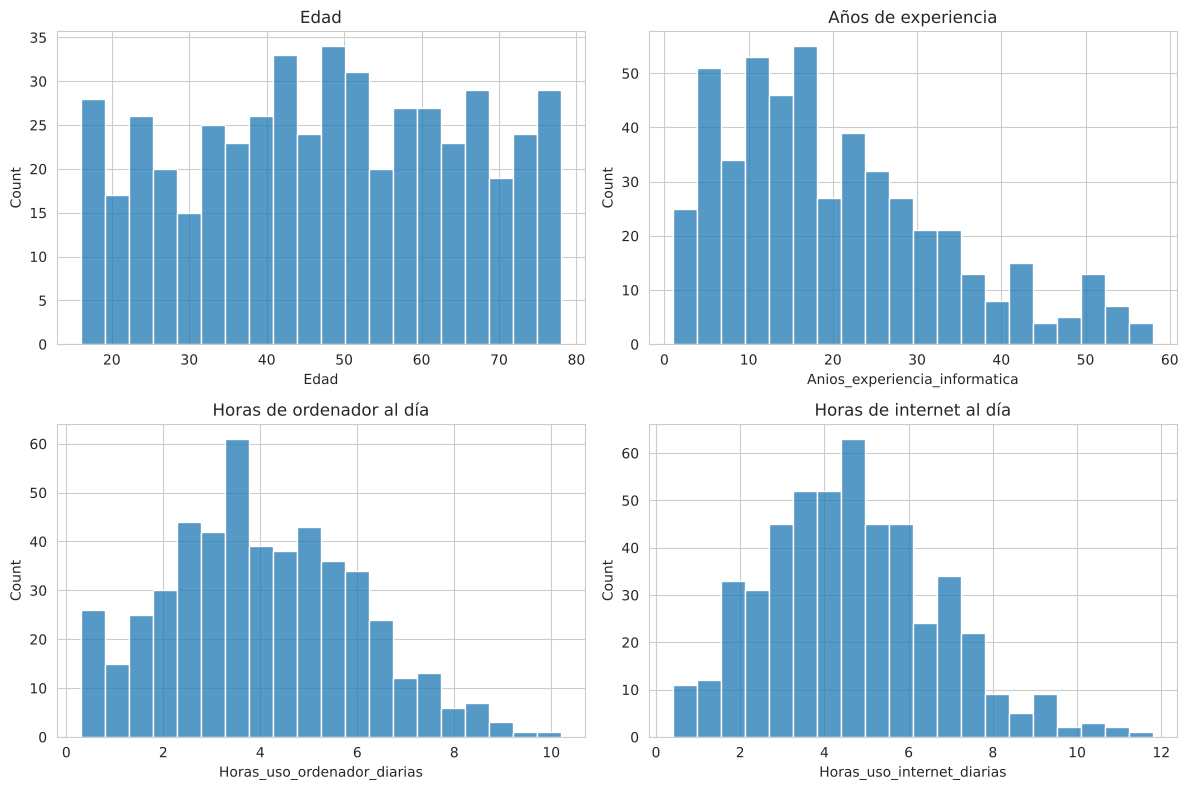

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(datos["Edad"], bins=20, ax=ax[0, 0])
ax[0, 0].set_title("Edad")
sns.histplot(datos["Anios_experiencia_informatica"], bins=20, ax=ax[0, 1])
ax[0, 1].set_title("Años de experiencia")
sns.histplot(datos["Horas_uso_ordenador_diarias"], bins=20, ax=ax[1, 0])
ax[1, 0].set_title("Horas de ordenador al día")
sns.histplot(datos["Horas_uso_internet_diarias"], bins=20, ax=ax[1, 1])
ax[1, 1].set_title("Horas de internet al día")
plt.tight_layout()
plt.savefig("graficos/01_histogramas.png", dpi=110)
plt.show()

### Diagramas de caja

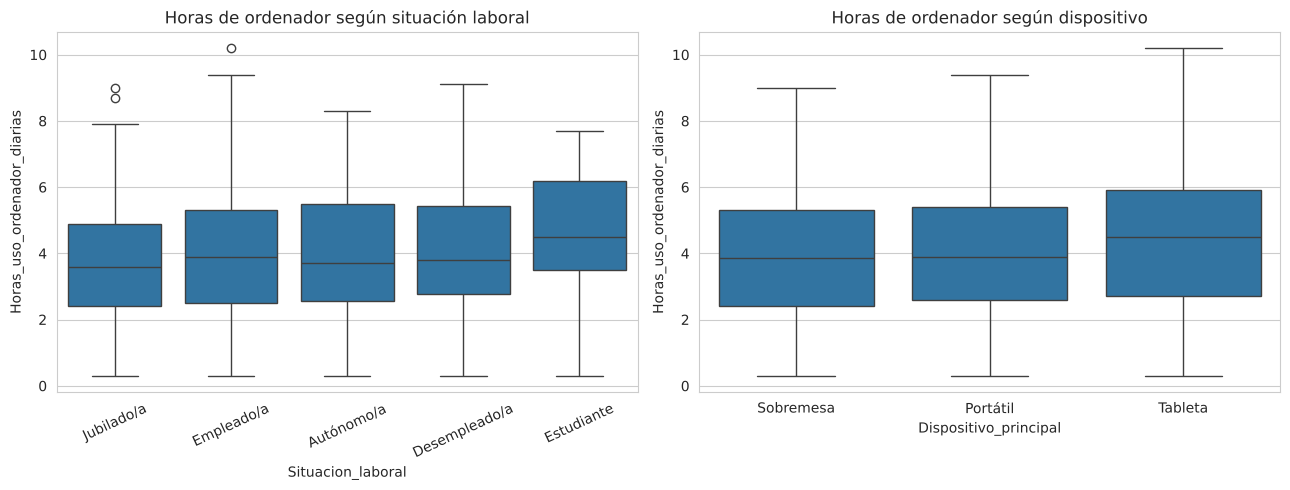

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=datos, x="Situacion_laboral", y="Horas_uso_ordenador_diarias", ax=ax[0])
ax[0].set_title("Horas de ordenador según situación laboral")
ax[0].tick_params(axis="x", rotation=25)
sns.boxplot(data=datos, x="Dispositivo_principal", y="Horas_uso_ordenador_diarias", ax=ax[1])
ax[1].set_title("Horas de ordenador según dispositivo")
plt.tight_layout()
plt.savefig("graficos/02_cajas_laboral_dispositivo.png", dpi=110)
plt.show()

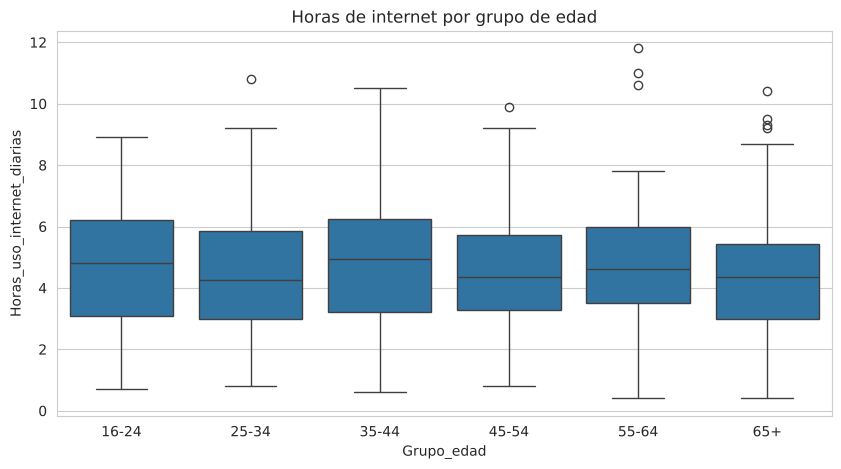

In [13]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=datos, x="Grupo_edad", y="Horas_uso_internet_diarias")
plt.title("Horas de internet por grupo de edad")
plt.savefig("graficos/03_caja_edad_internet.png", dpi=110)
plt.show()

### Gráficos de dispersión

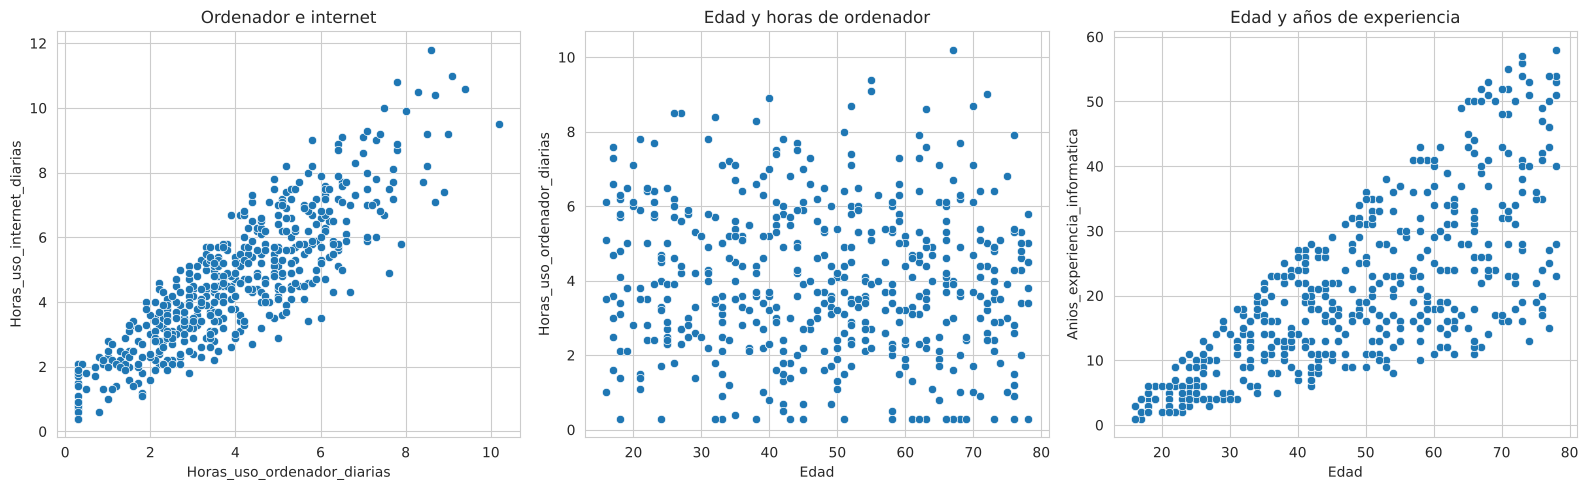

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
sns.scatterplot(data=datos, x="Horas_uso_ordenador_diarias", y="Horas_uso_internet_diarias", ax=ax[0])
ax[0].set_title("Ordenador e internet")
sns.scatterplot(data=datos, x="Edad", y="Horas_uso_ordenador_diarias", ax=ax[1])
ax[1].set_title("Edad y horas de ordenador")
sns.scatterplot(data=datos, x="Edad", y="Anios_experiencia_informatica", ax=ax[2])
ax[2].set_title("Edad y años de experiencia")
plt.tight_layout()
plt.savefig("graficos/04_dispersion.png", dpi=110)
plt.show()

### Gráficos de barras

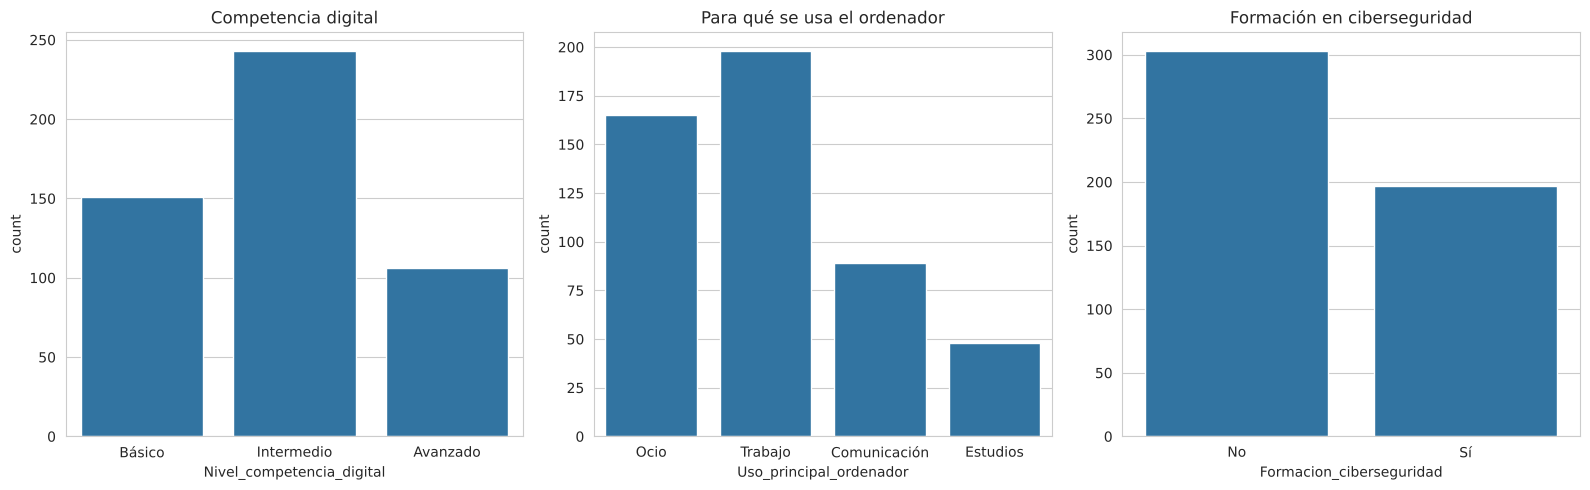

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
sns.countplot(data=datos, x="Nivel_competencia_digital", order=["Básico", "Intermedio", "Avanzado"], ax=ax[0])
ax[0].set_title("Competencia digital")
sns.countplot(data=datos, x="Uso_principal_ordenador", ax=ax[1])
ax[1].set_title("Para qué se usa el ordenador")
sns.countplot(data=datos, x="Formacion_ciberseguridad", ax=ax[2])
ax[2].set_title("Formación en ciberseguridad")
plt.tight_layout()
plt.savefig("graficos/05_barras.png", dpi=110)
plt.show()

### Correlaciones

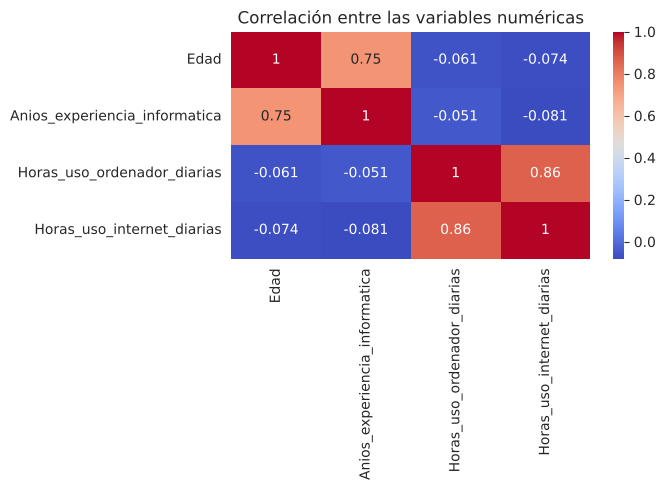

In [16]:
plt.figure(figsize=(7, 5))
sns.heatmap(datos[numericas].corr(), annot=True, cmap="coolwarm")
plt.title("Correlación entre las variables numéricas")
plt.tight_layout()
plt.savefig("graficos/06_correlacion.png", dpi=110)
plt.show()

## 4. Preguntas

### Pregunta 1: ¿Qué provincias usan más y menos el ordenador y internet?

In [17]:
provincias = datos.groupby("Provincia")[["Horas_uso_ordenador_diarias", "Horas_uso_internet_diarias"]].mean().round(2)

print("Las 5 que más usan el ordenador:")
print(provincias.sort_values("Horas_uso_ordenador_diarias", ascending=False).head(5))
print()
print("Las 5 que menos:")
print(provincias.sort_values("Horas_uso_ordenador_diarias").head(5))
print()
print("personas por provincia (mínimo y máximo):", datos.groupby("Provincia").size().min(), datos.groupby("Provincia").size().max())

Las 5 que más usan el ordenador:
            Horas_uso_ordenador_diarias  Horas_uso_internet_diarias
Provincia                                                          
Málaga                             5.11                        5.83
Cuenca                             4.91                        5.66
Pontevedra                         4.90                        6.03
Jaén                               4.86                        5.56
Ávila                              4.71                        5.40

Las 5 que menos:
            Horas_uso_ordenador_diarias  Horas_uso_internet_diarias
Provincia                                                          
Soria                              2.33                        3.32
Toledo                             2.79                        3.35
Cádiz                              3.16                        3.56
Las Palmas                         3.17                        3.33
La Rioja                           3.18                        3.

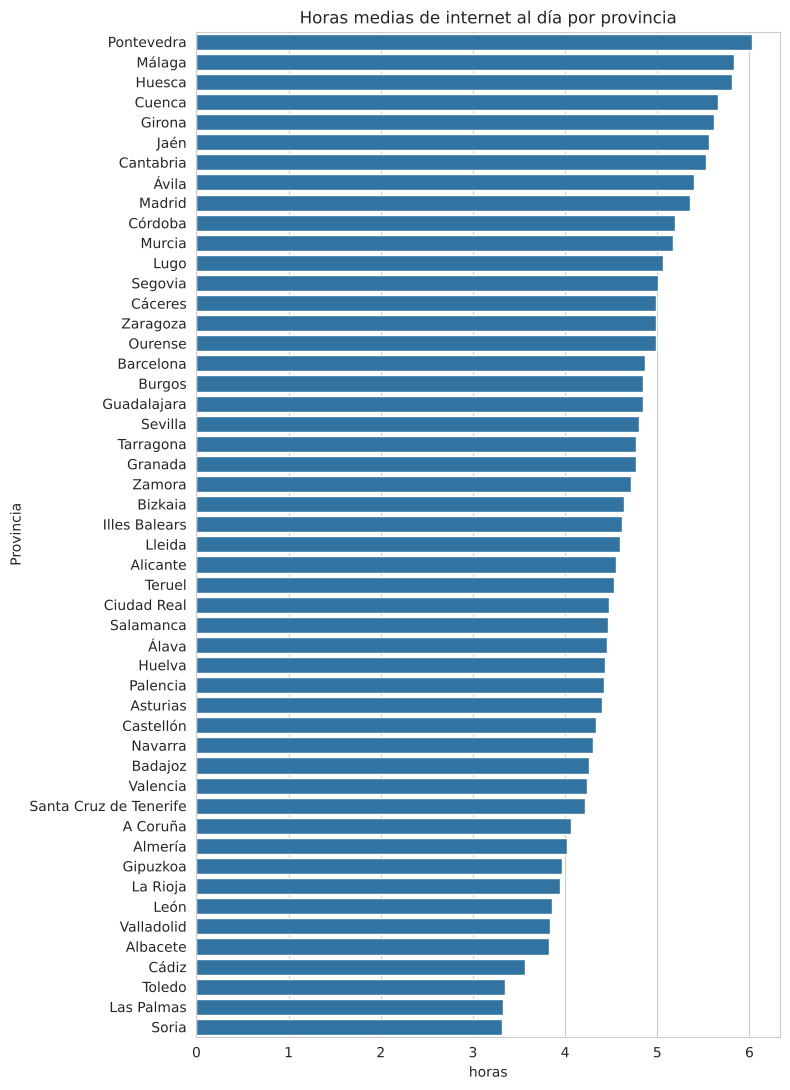

In [18]:
orden = provincias.sort_values("Horas_uso_internet_diarias", ascending=False)
plt.figure(figsize=(8, 11))
sns.barplot(x=orden["Horas_uso_internet_diarias"], y=orden.index)
plt.title("Horas medias de internet al día por provincia")
plt.xlabel("horas")
plt.tight_layout()
plt.savefig("graficos/07_provincias_internet.png", dpi=110)
plt.show()

Ojo: en cada provincia solo hay unas 10 personas, así que estas diferencias pueden ser casualidad.

### Pregunta 2: ¿Cambia el uso según la edad o la situación laboral?

In [19]:
print(datos.groupby("Grupo_edad", observed=True)["Horas_uso_ordenador_diarias"].mean().round(2))
print()
print(datos.groupby("Situacion_laboral")["Horas_uso_ordenador_diarias"].mean().round(2))
print()
print("correlación edad y horas de ordenador:", round(datos["Edad"].corr(datos["Horas_uso_ordenador_diarias"]), 2))

Grupo_edad
16-24    4.28
25-34    3.97
35-44    4.13
45-54    3.91
55-64    4.11
65+      3.81
Name: Horas_uso_ordenador_diarias, dtype: float64

Situacion_laboral
Autónomo/a       3.92
Desempleado/a    4.04
Empleado/a       4.01
Estudiante       4.57
Jubilado/a       3.69
Name: Horas_uso_ordenador_diarias, dtype: float64

correlación edad y horas de ordenador: -0.06


In [20]:
est = datos[datos["Situacion_laboral"] == "Estudiante"]["Horas_uso_ordenador_diarias"].mean()
resto = datos[datos["Situacion_laboral"] != "Estudiante"]["Horas_uso_ordenador_diarias"].mean()
print("estudiantes:", round(est, 2), "horas | el resto:", round(resto, 2), "horas")

estudiantes: 4.57 horas | el resto: 3.95 horas


### Pregunta 3: ¿Tener formación en ciberseguridad significa tener más nivel digital?

In [21]:
tabla = pd.crosstab(datos["Formacion_ciberseguridad"], datos["Nivel_competencia_digital"], normalize="index") * 100
tabla = tabla[["Básico", "Intermedio", "Avanzado"]].round(1)
print(tabla)
print()
print("% de gente con formación:", round((datos["Formacion_ciberseguridad"] == "Sí").mean() * 100, 1))

Nivel_competencia_digital  Básico  Intermedio  Avanzado
Formacion_ciberseguridad                               
No                           28.4        45.9      25.7
Sí                           33.0        52.8      14.2

% de gente con formación: 39.4


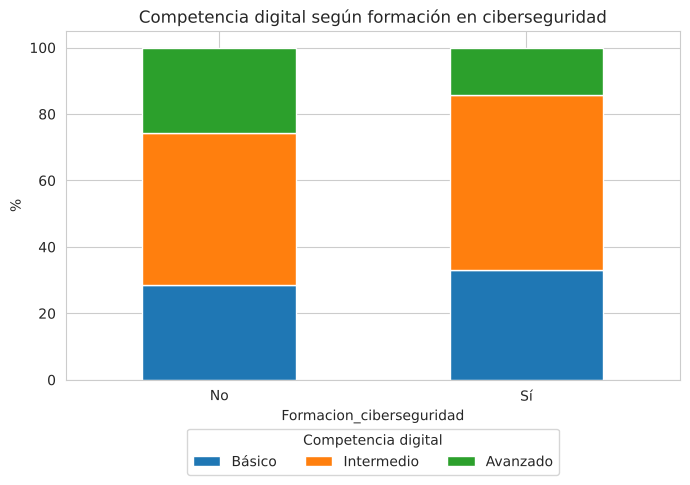

In [22]:
tabla.plot(kind="bar", stacked=True, figsize=(7, 5))
plt.title("Competencia digital según formación en ciberseguridad")
plt.ylabel("%")
plt.legend(title="Competencia digital", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("graficos/08_formacion_competencia.png", dpi=110)
plt.show()

In [23]:
# formación en ciberseguridad según el nivel de estudios
orden_estudios = ["Sin estudios", "Primaria", "ESO", "Bachillerato", "FP Grado Medio",
                  "FP Grado Superior", "Universidad", "Máster/Doctorado"]
por_estudios = datos.groupby("Nivel_estudios")["Formacion_ciberseguridad"].apply(lambda x: round((x == "Sí").mean() * 100, 1))
por_estudios.reindex(orden_estudios)

Nivel_estudios
Sin estudios         44.4
Primaria             35.3
ESO                  37.7
Bachillerato         42.1
FP Grado Medio       36.2
FP Grado Superior    38.2
Universidad          44.0
Máster/Doctorado     33.3
Name: Formacion_ciberseguridad, dtype: float64

### Pregunta 4: ¿Qué dispositivo se usa más y para qué?

In [24]:
print(datos["Dispositivo_principal"].value_counts(normalize=True).round(3) * 100)
print()
print(pd.crosstab(datos["Dispositivo_principal"], datos["Uso_principal_ordenador"], normalize="index").round(3) * 100)
print()
print(datos.groupby("Uso_principal_ordenador")["Horas_uso_ordenador_diarias"].mean().round(2))

Dispositivo_principal
Portátil     65.4
Sobremesa    29.6
Tableta       5.0
Name: proportion, dtype: float64

Uso_principal_ordenador  Comunicación  Estudios  Ocio  Trabajo
Dispositivo_principal                                         
Portátil                         20.2       9.2  30.0     40.7
Sobremesa                        14.2      11.5  37.8     36.5
Tableta                           8.0       4.0  44.0     44.0

Uso_principal_ordenador
Comunicación    3.98
Estudios        4.32
Ocio            4.00
Trabajo         3.97
Name: Horas_uso_ordenador_diarias, dtype: float64


### Pregunta 5: ¿Hay valores raros (outliers)?

In [25]:
q1 = datos["Horas_uso_ordenador_diarias"].quantile(0.25)
q3 = datos["Horas_uso_ordenador_diarias"].quantile(0.75)
limite = q3 + 1.5 * (q3 - q1)
raros = datos[datos["Horas_uso_ordenador_diarias"] > limite]
print("límite:", round(limite, 2), "horas")
print("personas por encima:", len(raros))
raros[["Edad", "Situacion_laboral", "Dispositivo_principal", "Horas_uso_ordenador_diarias"]]

límite: 9.56 horas
personas por encima: 1


,Edad,Situacion_laboral,Dispositivo_principal,Horas_uso_ordenador_diarias
286,67,Empleado/a,Tableta,10.2


## 5. Conclusiones

In [26]:
corr = datos[numericas].corr()
print("edad y experiencia:", round(corr.loc["Edad", "Anios_experiencia_informatica"], 2))
print("ordenador e internet:", round(corr.loc["Horas_uso_ordenador_diarias", "Horas_uso_internet_diarias"], 2))
print("media de ordenador:", round(datos["Horas_uso_ordenador_diarias"].mean(), 2))
print("media de internet:", round(datos["Horas_uso_internet_diarias"].mean(), 2))

edad y experiencia: 0.75
ordenador e internet: 0.86
media de ordenador: 4.01
media de internet: 4.64


- El dataset está limpio: 500 filas, sin nulos ni duplicados. Hemos quitado ID, nombre, apellidos y DNI.
- La gente usa el ordenador unas 4 horas al día y internet unas 4,6.
- Quien usa más el ordenador también usa más internet (correlación 0,86).
- La edad y los años de experiencia van muy juntos (0,75), pero la edad casi no cambia las horas de uso.
- Los estudiantes son los que más usan el ordenador (4,6 horas contra 3,9 del resto).
- Solo el 39 % tiene formación en ciberseguridad y, curiosamente, entre los que la tienen hay menos gente con nivel avanzado.
- Entre provincias hay diferencias pero con 10 personas por provincia no son fiables.
- No hemos podido ver las horas del día con más uso porque el dataset no tiene esa información.